In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
# Ensure the CSV file is in the same directory as your Jupyter Notebook
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Display the first 5 rows to verify successful loading
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Convert 'TotalCharges' to numeric, forcing errors (blank spaces) to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Drop rows with missing values (the 11 rows we found earlier)
df.dropna(inplace=True)

# Drop 'customerID' as it does not contribute to predicting churn
df.drop('customerID', axis=1, inplace=True)

# Check the new shape of the dataset
print("Data cleaning completed.")
print("Current dataset shape:", df.shape)

Data cleaning completed.
Current dataset shape: (7032, 20)


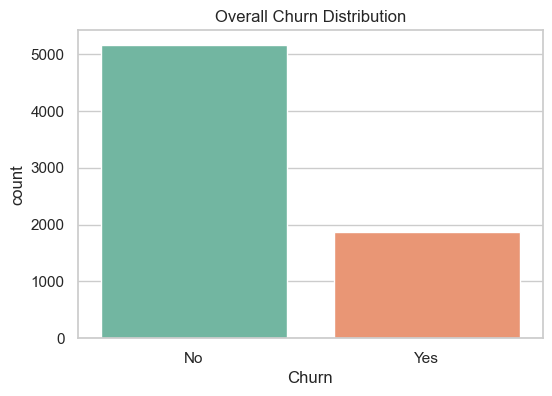

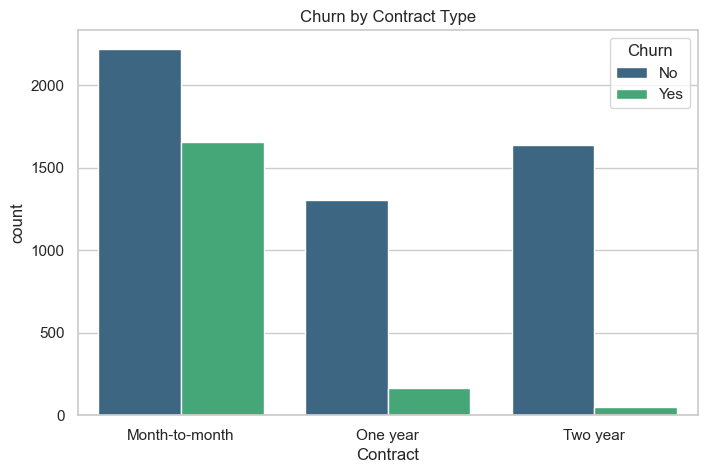

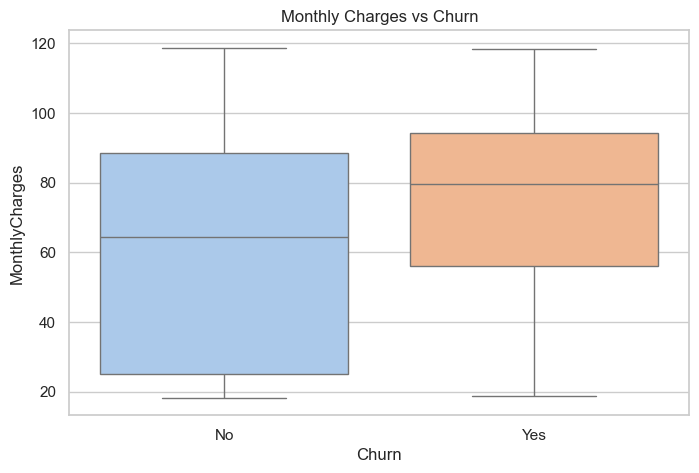

In [3]:
# Set seaborn style for better aesthetics
sns.set_theme(style="whitegrid")

# 1. Overall Churn Distribution
plt.figure(figsize=(6, 4))
# Added hue='Churn' and legend=False to fix the FutureWarning
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title('Overall Churn Distribution')
plt.show()

# 2. Churn based on Contract Type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='viridis')
plt.title('Churn by Contract Type')
plt.show()

# 3. Monthly Charges vs Churn
plt.figure(figsize=(8, 5))
# Added hue='Churn' and legend=False to fix the FutureWarning
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='pastel', legend=False)
plt.title('Monthly Charges vs Churn')
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

# Convert the target variable 'Churn' from Yes/No to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Convert all other categorical columns to numeric using One-Hot Encoding
df_encoded = pd.get_dummies(df, drop_first=True)

# Separate Features (X) and the Target variable (y)
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# Split the data into Training Data (80%) and Testing Data (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data preprocessing completed.")
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Data preprocessing completed.
Training features shape: (5625, 30)
Testing features shape: (1407, 30)


In [10]:
# Import models, metrics, and StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

# Step 5.1: Scale the features to a uniform range
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5.2: Initialize and train the Logistic Regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# Step 5.3: Make predictions using the testing data
y_pred = model.predict(X_test_scaled)

# Step 5.4: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 78.75%

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.62      0.52      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



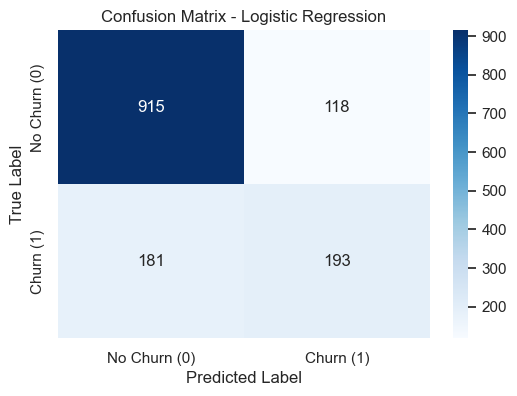

In [11]:
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix using a Seaborn heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Churn (0)', 'Churn (1)'], 
            yticklabels=['No Churn (0)', 'Churn (1)'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()